# Perbandingan N-gram TF-IDF + Logistic Regression (SATUSEHAT) — versi revisi
Perbaikan sesuai 5 poin revisi:
1. Pemilihan model berdasarkan CV, tidak menobatkan satu model "terbaik" dari akurasi uji
2. Audit manual kesalahan prediksi (ekspor + rekap)
3. Variasi `min_df` dan perbandingan pada ulasan yang sama
4. `TfidfVectorizer` di dalam `Pipeline` (fit ulang tiap fold)
5. Replikasi: seed tercatat + ekspor data hasil preprocessing

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy

from scipy.stats import binomtest
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
)

SEED = 42   # satu seed untuk SEMUA proses acak (sampling, split, model)
plt.rcParams['figure.dpi'] = 150
sns.set_theme(style="whitegrid")

# Catat versi untuk dicantumkan di artikel (poin 5)
print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scipy       :", scipy.__version__)
print("SEED        :", SEED)

Python      : 3.13.0
scikit-learn: 1.7.2
pandas      : 2.3.3
numpy       : 2.3.4
scipy       : 1.16.3
SEED        : 42


## Langkah 0 (opsional) — Sampling dengan seed tercatat (poin 5)
Jalankan hanya jika kamu mengulang pengambilan 2.000 positif + 2.000 negatif dari data mentah IGAR.
Ubah `RUN_SAMPLING = True` dan sesuaikan nama file/kolom. **Kalau diulang, dataset berubah sehingga semua angka di artikel ikut berubah.**
Kalau `False`, notebook memakai `SATUSEHAT_clean_balanced.csv` yang sudah ada.

In [2]:
RUN_SAMPLING = False
RAW_FILE = 'IGAR_SATUSEHAT_raw.csv'   # sesuaikan: file subset SATUSEHAT dari IGAR v3

if RUN_SAMPLING:
    raw = pd.read_csv(RAW_FILE, sep=';')                  # sesuaikan separator
    raw = raw[raw['labelScoreBase'].isin(['Positive', 'Negative'])]   # skor 3 dibuang
    raw = raw.dropna(subset=['content']).drop_duplicates(subset=['content'])
    pos = raw[raw['labelScoreBase'] == 'Positive'].sample(n=2000, random_state=SEED)
    neg = raw[raw['labelScoreBase'] == 'Negative'].sample(n=2000, random_state=SEED)
    sampled = pd.concat([pos, neg]).sample(frac=1, random_state=SEED).reset_index(drop=True)
    sampled.to_csv('SATUSEHAT_sampled_seed42.csv', sep=';', index=False)
    print("Sampel tersimpan:", sampled.shape)
    # Lanjutkan: lakukan pembersihan seperti sebelumnya, lalu simpan sebagai SATUSEHAT_clean_balanced.csv

## Langkah 1 — Muat data dan bagi data

In [3]:
df = pd.read_csv('SATUSEHAT_clean_balanced.csv', sep=';')
df['label'] = df['labelScoreBase'].map({'Positive': 1, 'Negative': 0})
df['content'] = df['content'].astype(str)

X = df['content']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("Total Data      :", len(df))
print("Data Latih (80%):", len(X_train))
print("Data Uji (20%)  :", len(X_test))

# Ekspor data hasil preprocessing + penanda split (poin 5) -> unggah ke GitHub/Zenodo
export = df.copy()
export['split'] = 'train'
export.loc[X_test.index, 'split'] = 'test'
export.to_csv('SATUSEHAT_preprocessed_split.csv', sep=';', index=True, index_label='row_id')
print("Tersimpan: SATUSEHAT_preprocessed_split.csv")

Total Data      : 3994
Data Latih (80%): 3195
Data Uji (20%)  : 799
Tersimpan: SATUSEHAT_preprocessed_split.csv


## Langkah 2 — Eksperimen utama (min_df = 3, C disetel lewat CV)
`TfidfVectorizer` ada **di dalam Pipeline**, jadi dihitung ulang di setiap fold (poin 4).

In [4]:
experiments = [
    ("Unigram", (1, 1)),
    ("Bigram", (2, 2)),
    ("Unigram + Bigram", (1, 2)),
]
C_GRID = [0.01, 0.1, 1.0, 10.0]
MIN_DF_MAIN = 3

def make_pipeline(ngram, min_df):
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=ngram, min_df=min_df)),
        ('classifier', LogisticRegression(max_iter=1000, random_state=SEED)),
    ])

def fit_config(ngram, min_df):
    gs = GridSearchCV(
        make_pipeline(ngram, min_df),
        param_grid={'classifier__C': C_GRID},
        cv=5, scoring='accuracy', n_jobs=-1,
    )
    gs.fit(X_train, y_train)
    return gs

results_main, models_dict = [], {}
for name, ngram in experiments:
    gs = fit_config(ngram, MIN_DF_MAIN)
    best = gs.best_estimator_
    y_pred = best.predict(X_test)
    y_prob = best.predict_proba(X_test)[:, 1]
    models_dict[name] = {'best_model': best, 'grid': gs, 'y_pred': y_pred, 'y_prob': y_prob}

    vec = best.named_steps['tfidf']
    results_main.append({
        'Skema N-Gram': name,
        'Best C': gs.best_params_['classifier__C'],
        'Total Fitur': len(vec.get_feature_names_out()),
        'Akurasi CV': gs.best_score_,
        'Akurasi Test': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'Ulasan uji tanpa fitur': int((vec.transform(X_test).getnnz(axis=1) == 0).sum()),
    })

df_results = pd.DataFrame(results_main)
print("=== HASIL N-GRAM (min_df = 3) ===")
print(df_results.round(4).to_string(index=False))

=== HASIL N-GRAM (min_df = 3) ===
    Skema N-Gram  Best C  Total Fitur  Akurasi CV  Akurasi Test  Precision  Recall  F1-Score  ROC-AUC  Ulasan uji tanpa fitur
         Unigram     1.0         1417      0.8194        0.8310     0.8438  0.8120    0.8276   0.9032                      33
          Bigram     1.0         1916      0.7531        0.7584     0.7239  0.8346    0.7753   0.8193                     205
Unigram + Bigram     1.0         3333      0.8210        0.8398     0.8575  0.8145    0.8355   0.9009                      33


## Poin 1 — Kriteria pemilihan model
Model acuan dipilih berdasarkan **akurasi CV**, bukan akurasi uji. Data uji hanya untuk pelaporan akhir.

In [5]:
idx = df_results['Akurasi CV'].idxmax()
selected_name = df_results.loc[idx, 'Skema N-Gram']
print(f"Konfigurasi dengan akurasi CV tertinggi: {selected_name} "
      f"({df_results.loc[idx, 'Akurasi CV']*100:.2f}%)")
print(df_results[['Skema N-Gram', 'Akurasi CV', 'Akurasi Test']].round(4).to_string(index=False))
print()
print("Catatan: jika selisih antar-konfigurasi tidak signifikan (lihat McNemar di bawah),")
print("laporkan ketiganya setara dan JANGAN menyebut satu pun 'terbaik' di artikel.")

Konfigurasi dengan akurasi CV tertinggi: Unigram + Bigram (82.10%)
    Skema N-Gram  Akurasi CV  Akurasi Test
         Unigram      0.8194        0.8310
          Bigram      0.7531        0.7584
Unigram + Bigram      0.8210        0.8398

Catatan: jika selisih antar-konfigurasi tidak signifikan (lihat McNemar di bawah),
laporkan ketiganya setara dan JANGAN menyebut satu pun 'terbaik' di artikel.


## Tabel 4 — Akurasi CV per nilai C

In [6]:
cv_summary = []
for name, info in models_dict.items():
    res = info['grid'].cv_results_
    row = {'Konfigurasi': name}
    for c_val, score in zip(res['param_classifier__C'].data, res['mean_test_score']):
        row[f'C = {c_val}'] = f"{score*100:.2f}%"
    cv_summary.append(row)
df_tabel4 = pd.DataFrame(cv_summary)
print(df_tabel4.to_string(index=False))

     Konfigurasi C = 0.01 C = 0.1 C = 1.0 C = 10.0
         Unigram   78.56%  80.00%  81.94%   80.38%
          Bigram   75.02%  75.02%  75.31%   74.18%
Unigram + Bigram   79.44%  80.78%  82.10%   80.53%


## Tabel 6 — Akurasi latih, uji, dan selisih terhadap CV

In [7]:
rows = []
for name, info in models_dict.items():
    m = info['best_model']
    acc_train = accuracy_score(y_train, m.predict(X_train))
    acc_test = accuracy_score(y_test, info['y_pred'])
    acc_cv = info['grid'].best_score_
    rows.append({
        'Konfigurasi': name,
        'Akurasi latih': f"{acc_train*100:.2f}%",
        'Akurasi uji': f"{acc_test*100:.2f}%",
        'Selisih latih-uji': round((acc_train - acc_test)*100, 2),
        'Selisih latih-CV': round((acc_train - acc_cv)*100, 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

     Konfigurasi Akurasi latih Akurasi uji  Selisih latih-uji  Selisih latih-CV
         Unigram        87.39%      83.10%               4.28              5.45
          Bigram        86.01%      75.84%              10.16             10.70
Unigram + Bigram        89.08%      83.98%               5.10              6.98


## Classification report rinci

In [8]:
for name, info in models_dict.items():
    print("=" * 60)
    print("CLASSIFICATION REPORT:", name.upper())
    print("=" * 60)
    print(classification_report(y_test, info['y_pred'], target_names=['Negative', 'Positive']))

CLASSIFICATION REPORT: UNIGRAM
              precision    recall  f1-score   support

    Negative       0.82      0.85      0.83       400
    Positive       0.84      0.81      0.83       399

    accuracy                           0.83       799
   macro avg       0.83      0.83      0.83       799
weighted avg       0.83      0.83      0.83       799

CLASSIFICATION REPORT: BIGRAM
              precision    recall  f1-score   support

    Negative       0.81      0.68      0.74       400
    Positive       0.72      0.83      0.78       399

    accuracy                           0.76       799
   macro avg       0.76      0.76      0.76       799
weighted avg       0.76      0.76      0.76       799

CLASSIFICATION REPORT: UNIGRAM + BIGRAM
              precision    recall  f1-score   support

    Negative       0.82      0.86      0.84       400
    Positive       0.86      0.81      0.84       399

    accuracy                           0.84       799
   macro avg       0.84    

## Uji McNemar berpasangan (ketiga pasangan)
Eksak (binomial dua sisi). Sebelumnya hanya unigram vs unigram+bigram; sekarang bigram juga diuji berpasangan.

In [9]:
def mcnemar_exact(pred_a, pred_b, y_true):
    ok_a = (np.asarray(pred_a) == np.asarray(y_true))
    ok_b = (np.asarray(pred_b) == np.asarray(y_true))
    b = int((ok_a & ~ok_b).sum())   # hanya A benar
    c = int((~ok_a & ok_b).sum())   # hanya B benar
    n = b + c
    p = 1.0 if n == 0 else binomtest(min(b, c), n, 0.5).pvalue
    return b, c, p

names = [n for n, _ in experiments]
pairs = [(names[0], names[2]), (names[0], names[1]), (names[1], names[2])]

def mcnemar_table(mask=None):
    rows = []
    yt = y_test.values if mask is None else y_test.values[mask]
    for a, b_ in pairs:
        pa = models_dict[a]['y_pred']; pb = models_dict[b_]['y_pred']
        if mask is not None:
            pa, pb = pa[mask], pb[mask]
        only_a, only_b, p = mcnemar_exact(pa, pb, yt)
        rows.append({'A': a, 'B': b_, 'hanya A benar': only_a,
                     'hanya B benar': only_b, 'p-value': round(p, 4)})
    return pd.DataFrame(rows)

print("=== McNemar, seluruh data uji ===")
print(mcnemar_table().to_string(index=False))

=== McNemar, seluruh data uji ===
      A                B  hanya A benar  hanya B benar  p-value
Unigram Unigram + Bigram             11             18   0.2649
Unigram           Bigram            103             45   0.0000
 Bigram Unigram + Bigram             35            100   0.0000


## Poin 3 — Bandingkan pada ulasan yang SAMA
Bigram saja membuat sebagian ulasan uji bervektor nol (tanpa fitur). Di sini ketiga model dibandingkan
hanya pada ulasan uji yang **punya fitur bigram**, sehingga perbandingannya adil.

In [10]:
vec_bi = models_dict['Bigram']['best_model'].named_steps['tfidf']
has_bigram = vec_bi.transform(X_test).getnnz(axis=1) > 0
print(f"Ulasan uji dengan fitur bigram: {has_bigram.sum()} dari {len(X_test)} "
      f"({has_bigram.mean()*100:.1f}%)")

rows = []
for name, info in models_dict.items():
    acc_all = accuracy_score(y_test, info['y_pred'])
    acc_sub = accuracy_score(y_test[has_bigram], info['y_pred'][has_bigram])
    rows.append({'Konfigurasi': name,
                 'Akurasi semua uji': round(acc_all*100, 2),
                 'Akurasi subset (ada fitur bigram)': round(acc_sub*100, 2)})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("=== McNemar pada subset yang sama ===")
print(mcnemar_table(mask=has_bigram).to_string(index=False))

Ulasan uji dengan fitur bigram: 594 dari 799 (74.3%)
     Konfigurasi  Akurasi semua uji  Akurasi subset (ada fitur bigram)
         Unigram              83.10                              85.19
          Bigram              75.84                              78.62
Unigram + Bigram              83.98                              85.35

=== McNemar pada subset yang sama ===
      A                B  hanya A benar  hanya B benar  p-value
Unigram Unigram + Bigram             10             11   1.0000
Unigram           Bigram             68             29   0.0001
 Bigram Unigram + Bigram             19             59   0.0000


## Poin 3 — Sensitivitas `min_df`
Setiap konfigurasi n-gram dijalankan dengan `min_df` ∈ {1, 2, 3, 5}; C disetel lewat CV di dalam Pipeline.

In [11]:
MIN_DF_LIST = [1, 2, 3, 5]
rows = []
for name, ngram in experiments:
    for md_ in MIN_DF_LIST:
        gs = fit_config(ngram, md_)
        best = gs.best_estimator_
        pred = best.predict(X_test)
        vec = best.named_steps['tfidf']
        rows.append({
            'Skema N-Gram': name,
            'min_df': md_,
            'Best C': gs.best_params_['classifier__C'],
            'Total Fitur': len(vec.get_feature_names_out()),
            'Akurasi CV': round(gs.best_score_*100, 2),
            'Akurasi Test': round(accuracy_score(y_test, pred)*100, 2),
            'Uji tanpa fitur': int((vec.transform(X_test).getnnz(axis=1) == 0).sum()),
        })
df_mindf = pd.DataFrame(rows)
print(df_mindf.to_string(index=False))
df_mindf.to_csv('hasil_sensitivitas_min_df.csv', index=False)

    Skema N-Gram  min_df  Best C  Total Fitur  Akurasi CV  Akurasi Test  Uji tanpa fitur
         Unigram       1     1.0         5702       82.16         84.36               27
         Unigram       2     1.0         2046       82.25         83.23               29
         Unigram       3     1.0         1417       81.94         83.10               33
         Unigram       5     1.0          972       81.97         82.73               34
          Bigram       1     1.0        25119       77.03         77.35              135
          Bigram       2     1.0         3986       76.18         76.60              171
          Bigram       3     1.0         1916       75.31         75.84              205
          Bigram       5     0.1          844       73.93         75.34              236
Unigram + Bigram       1    10.0        30821       82.13         84.73               27
Unigram + Bigram       2     1.0         6032       82.03         83.85               29
Unigram + Bigram     

## Poin 2 — Audit manual kesalahan prediksi
Ekspor semua ulasan uji yang salah diprediksi (model Unigram + Bigram, seharusnya 128 baris).
Buka `audit_kesalahan.csv` di Excel, isi kolom `label_teks` dan `kategori` sendiri.

In [12]:
AUDIT_MODEL = "Unigram + Bigram"
pred = models_dict[AUDIT_MODEL]['y_pred']
prob = models_dict[AUDIT_MODEL]['y_prob']
mask = (pred != y_test.values)

errors = pd.DataFrame({
    'row_id': y_test.index[mask],
    'content': X_test.values[mask],
    'label_bintang': y_test.values[mask],     # 1 = Positive, 0 = Negative
    'prediksi': pred[mask],
    'prob_positif': np.round(prob[mask], 3),
    'jenis_error': np.where(pred[mask] == 1, 'FP', 'FN'),
})
errors['label_teks'] = ''   # isi: positif / negatif / ambigu  (menurut ISI TEKS, bukan bintang)
errors['kategori'] = ''     # isi salah satu kategori di bawah
errors['catatan'] = ''
errors.to_csv('audit_kesalahan.csv', sep=';', index=False)
print("Jumlah kesalahan:", len(errors), "(FP:", (errors.jenis_error == 'FP').sum(),
      ", FN:", (errors.jenis_error == 'FN').sum(), ")")
print()
print("Saran kategori (pakai nama persis ini):")
print(" - derau_label        : isi teks tidak cocok dengan bintang (label bintang yang keliru)")
print(" - teks_ambigu        : teks pendek/tanpa kata sentimen, sulit dinilai")
print(" - negasi_tidak_baku  : kesalahan karena negasi atau kata tidak baku (gak/ga/tdk)")
print(" - keluhan_teknis     : keluhan teknis tanpa kata negatif umum")
print(" - kesalahan_model    : label benar dan teks jelas, model tetap salah")

Jumlah kesalahan: 128 (FP: 54 , FN: 74 )

Saran kategori (pakai nama persis ini):
 - derau_label        : isi teks tidak cocok dengan bintang (label bintang yang keliru)
 - teks_ambigu        : teks pendek/tanpa kata sentimen, sulit dinilai
 - negasi_tidak_baku  : kesalahan karena negasi atau kata tidak baku (gak/ga/tdk)
 - keluhan_teknis     : keluhan teknis tanpa kata negatif umum
 - kesalahan_model    : label benar dan teks jelas, model tetap salah


Setelah `audit_kesalahan.csv` selesai diisi, simpan sebagai `audit_kesalahan_terisi.csv`, lalu jalankan sel rekap ini.

In [13]:
AUDIT_FILE = 'audit_kesalahan_terisi.csv'
if os.path.exists(AUDIT_FILE):
    aud = pd.read_csv(AUDIT_FILE, sep=';')
    aud = aud[aud['kategori'].notna() & (aud['kategori'].astype(str).str.strip() != '')]
    total = len(aud)
    rekap = aud['kategori'].value_counts().rename('jumlah').to_frame()
    rekap['persen'] = (rekap['jumlah'] / total * 100).round(1)
    print(f"Ulasan teraudit: {total}")
    print(rekap)
else:
    print(f"Belum ada {AUDIT_FILE}. Isi dulu audit_kesalahan.csv lalu simpan dengan nama itu.")

Belum ada audit_kesalahan_terisi.csv. Isi dulu audit_kesalahan.csv lalu simpan dengan nama itu.


## Fitur paling berpengaruh (koefisien)

In [14]:
def top_features(name, k=5):
    pipe = models_dict[name]['best_model']
    vec = pipe.named_steps['tfidf']
    coef = pipe.named_steps['classifier'].coef_[0]
    feats = np.array(vec.get_feature_names_out())
    order = np.argsort(coef)
    neg = list(zip(feats[order[:k]], coef[order[:k]].round(3)))
    pos = list(zip(feats[order[::-1][:k]], coef[order[::-1][:k]].round(3)))
    print(f"--- {name} ---")
    print("Positif:", pos)
    print("Negatif:", neg)

for n in ["Unigram", "Unigram + Bigram", "Bigram"]:
    top_features(n)

--- Unigram ---
Positif: [('bagus', np.float64(3.23)), ('membantu', np.float64(3.088)), ('sangat', np.float64(2.594)), ('mantap', np.float64(2.478)), ('semoga', np.float64(1.845))]
Negatif: [('tidak', np.float64(-3.658)), ('gak', np.float64(-3.205)), ('padahal', np.float64(-2.493)), ('kurang', np.float64(-2.444)), ('malah', np.float64(-2.376))]
--- Unigram + Bigram ---
Positif: [('bagus', np.float64(3.254)), ('membantu', np.float64(2.897)), ('sangat', np.float64(2.531)), ('mantap', np.float64(2.474)), ('ok', np.float64(1.822))]
Negatif: [('tidak', np.float64(-3.654)), ('gak', np.float64(-3.149)), ('aplikasi', np.float64(-2.454)), ('padahal', np.float64(-2.406)), ('ga', np.float64(-2.258))]
--- Bigram ---
Positif: [('sangat membantu', np.float64(3.344)), ('terima kasih', np.float64(2.036)), ('sangat bermanfaat', np.float64(1.657)), ('bagus dan', np.float64(1.627)), ('sangat bagus', np.float64(1.594))]
Negatif: [('gak bisa', np.float64(-2.757)), ('tidak bisa', np.float64(-2.183)), ('ga b

## Visualisasi (tanpa label "terbaik")

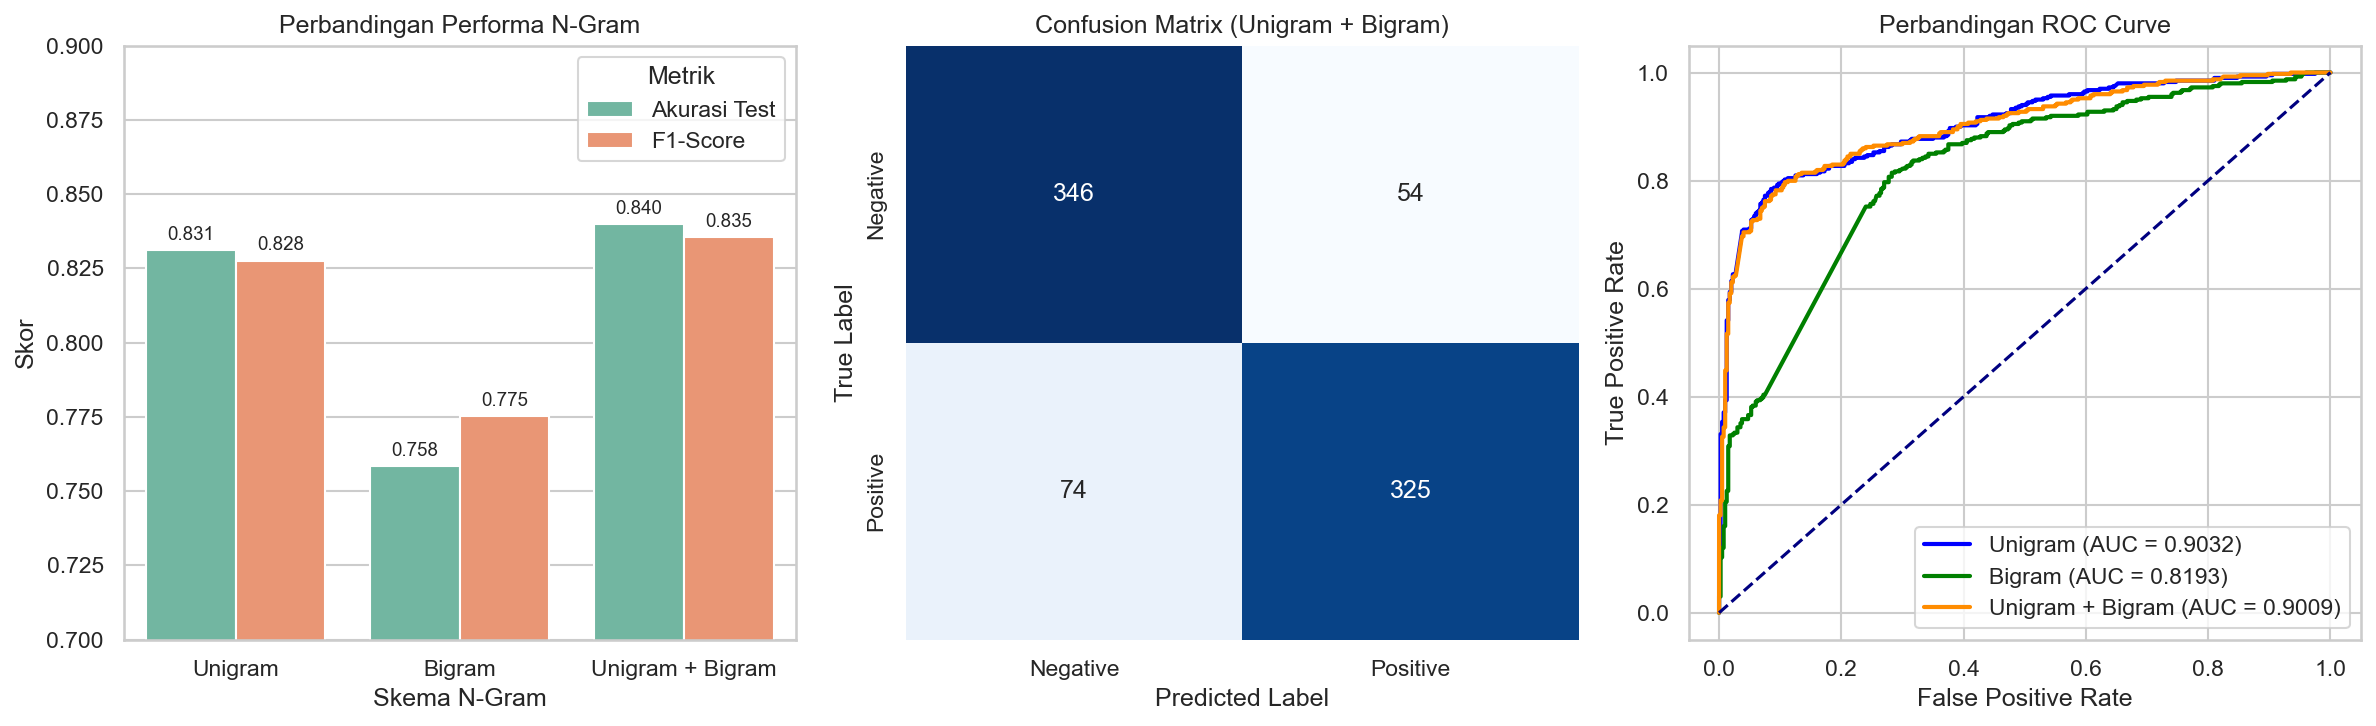

In [15]:
fig = plt.figure(figsize=(16, 5))

ax1 = plt.subplot(1, 3, 1)
df_plot = df_results.melt(id_vars=['Skema N-Gram'], value_vars=['Akurasi Test', 'F1-Score'],
                          var_name='Metrik', value_name='Skor')
sns.barplot(data=df_plot, x='Skema N-Gram', y='Skor', hue='Metrik', palette='Set2', ax=ax1)
ax1.set_title('Perbandingan Performa N-Gram')
ax1.set_ylim(0.7, 0.9)
for p in ax1.patches:
    if p.get_height() > 0:
        ax1.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

ax2 = plt.subplot(1, 3, 2)
cm_name = "Unigram + Bigram"    # dipakai untuk analisis kesalahan, BUKAN karena "terbaik"
cm = confusion_matrix(y_test, models_dict[cm_name]['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax2, cbar=False,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
ax2.set_title(f'Confusion Matrix ({cm_name})')
ax2.set_xlabel('Predicted Label'); ax2.set_ylabel('True Label')

ax3 = plt.subplot(1, 3, 3)
colors = {'Unigram': 'blue', 'Bigram': 'green', 'Unigram + Bigram': 'darkorange'}
for name in models_dict:
    fpr, tpr, _ = roc_curve(y_test, models_dict[name]['y_prob'])
    auc_val = df_results.loc[df_results['Skema N-Gram'] == name, 'ROC-AUC'].values[0]
    ax3.plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.4f})', color=colors[name], lw=2)
ax3.plot([0, 1], [0, 1], color='navy', linestyle='--')
ax3.set_xlabel('False Positive Rate'); ax3.set_ylabel('True Positive Rate')
ax3.set_title('Perbandingan ROC Curve'); ax3.legend(loc='lower right')

plt.tight_layout()
plt.show()